# Preparación del subconjunto EuroSAT multiespectral

Preparamos los datos del proyecto **Ojo en órbita**. Partimos de 27.000 imágenes de 64 × 64 píxeles y buscamos un subconjunto equilibrado de **800 imágenes por clase: 8.000 en total**.

Utilizamos los archivos multiespectrales de EuroSAT para disponer de las bandas visibles RGB y del infrarrojo cercano B08. Obtenemos también la localización de cada imagen a partir de su georreferenciación.

La selección buscará mantener, dentro de cada clase, la proporción de imágenes de las distintas zonas geográficas mediante un muestreo estratificado proporcional.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import rasterio
from PIL import Image
from tqdm.auto import tqdm
import shutil

/Users/antonpg/Documents/UPM/Ciencia de datos/4. Cuarto Curso/Primer Semestre/Algoritmos y Arquitecturas para Procesado de Imágenes/Proyecto-AAPI/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Imágenes multiespectrales disponibles por clase

Construimos la tabla `inventory` a partir de los archivos `.tif` de `data/EuroSAT_MS/`. Cada fila contiene la ruta (`path`) y la clase (`class_name`) de una imagen. Ordenamos las carpetas y los archivos para mantener un recorrido reproducible.

Comparamos las imágenes disponibles (`available`) con el objetivo de 800 (`target`). La columna `surplus` indica cuántas sobran respecto a ese objetivo.

In [2]:
MS_DIR = Path("data/EuroSAT_MS")
IMAGES_PER_CLASS = 800

if not MS_DIR.is_dir():
    raise FileNotFoundError(f"Directory not found: {MS_DIR.resolve()}")

records = []

for class_dir in sorted(MS_DIR.iterdir()):
    for image_path in sorted(class_dir.glob("*.tif")):
        records.append({
            "path": image_path.as_posix(),
            "class_name": class_dir.name,
        })

inventory = pd.DataFrame(records, columns=["path", "class_name"])

summary = (
    inventory.groupby("class_name")
    .size()
    .rename("available")
    .to_frame()
)

summary["target"] = IMAGES_PER_CLASS
summary["surplus"] = summary["available"] - summary["target"]

display(summary)
print(f"Total images: {len(inventory):,}")

,available,target,surplus
class_name,,,
AnnualCrop,3000,800,2200
Forest,3000,800,2200
HerbaceousVegetation,3000,800,2200
Highway,2500,800,1700
Industrial,2500,800,1700
Pasture,2000,800,1200
PermanentCrop,2500,800,1700
Residential,3000,800,2200
River,2500,800,1700


Total images: 27,000


## Localización de las imágenes

Para preparar el muestreo, agruparemos las imágenes mediante una **cuadrícula regular**. Primero calculamos el centro de cada TIFF a partir de su georreferenciación.

Conservamos el CRS y las coordenadas originales (`crs`, `x`, `y`). Transformamos cada centro a dos sistemas comunes:

- **EPSG:4326**: longitud y latitud en grados, para localizar los parches en un mapa.
- **EPSG:3035**: coordenadas en metros (`x_3035_m`, `y_3035_m`), para construir una cuadrícula común a todos los parches. Esta proyección conserva las áreas y se utiliza en las cuadrículas europeas de referencia.

El CRS original se utiliza para transformar las coordenadas. Los estratos del muestreo serán las celdas de la cuadrícula.

In [3]:
from rasterio.warp import transform

GRID_CRS = "EPSG:3035"
geo_records = []

with rasterio.Env():
    for record in tqdm(
        inventory.itertuples(index=False),
        total=len(inventory),
        desc="Reading georeferencing",
    ):
        with rasterio.open(record.path) as src:
            # Centro geométrico del parche en su sistema de coordenadas
            x, y = src.transform * (src.width / 2, src.height / 2)
            geo_records.append({
                "path": record.path,
                "crs": src.crs.to_string(),
                "x": x,
                "y": y,
            })

geo = pd.DataFrame(geo_records)
geo[["longitude", "latitude", "x_3035_m", "y_3035_m"]] = np.nan

# Transformamos juntos los centros que comparten CRS original
for crs, group in geo.groupby("crs"):
    longitudes, latitudes = transform(
        crs, "EPSG:4326", group["x"].to_numpy(), group["y"].to_numpy()
    )
    grid_x, grid_y = transform(
        crs, GRID_CRS, group["x"].to_numpy(), group["y"].to_numpy()
    )
    geo.loc[group.index, "longitude"] = longitudes
    geo.loc[group.index, "latitude"] = latitudes
    geo.loc[group.index, "x_3035_m"] = grid_x
    geo.loc[group.index, "y_3035_m"] = grid_y

# Unimos por ruta
inventory = inventory[["path", "class_name"]].merge(
    geo,
    on="path",
    how="left",
    validate="one_to_one",
)

print(f"Located images: {len(inventory):,}")
display(inventory[["path", "class_name", "latitude", "longitude", "x_3035_m", "y_3035_m"]].head())


Reading georeferencing: 100%|██████████| 27000/27000 [00:16<00:00, 1619.31it/s]


Located images: 27,000


,path,class_name,latitude,longitude,x_3035_m,y_3035_m
0,data/EuroSAT_MS/AnnualCrop/AnnualCrop_1.tif,AnnualCrop,44.035220,28.559055,5.794695e+06,2.509109e+06
1,data/EuroSAT_MS/AnnualCrop/AnnualCrop_10.tif,AnnualCrop,39.085801,-1.829726,3.295845e+06,1.857311e+06
2,data/EuroSAT_MS/AnnualCrop/AnnualCrop_100.tif,AnnualCrop,48.977295,4.239720,3.899690e+06,2.890276e+06
3,data/EuroSAT_MS/AnnualCrop/AnnualCrop_1000.tif,AnnualCrop,48.892610,4.089878,3.888017e+06,2.881754e+06
4,data/EuroSAT_MS/AnnualCrop/AnnualCrop_1001.tif,AnnualCrop,51.832851,18.084960,4.877005e+06,3.222269e+06


### Comparación de cuadrículas de 100 y 200 km

Probamos cuadrados de **100 × 100 km** y **200 × 200 km** en EPSG:3035. Ambos tamaños comparten el origen fijo `(0, 0)` de este sistema, de modo que cada celda de 200 km agrupa cuatro celdas de 100 km.

Para obtener la columna y la fila de una celda, dividimos las coordenadas en metros por el tamaño de lado y redondeamos hacia abajo. Por ejemplo, un centro con `x = 350.000 m`, `y = 450.000 m` pertenece a la columna 3 y fila 4 de la cuadrícula de 100 km.

Añadimos al inventario `grid_100km` y `grid_200km`, que identifican la celda de cada imagen. En `grid_distribution`, contamos las imágenes de cada combinación **clase × celda** y calculamos:

- `percentage`: porcentaje respecto al total de esa misma clase.
- `ideal_quota`: número proporcional de imágenes que correspondería a esa celda al seleccionar 800 de esa clase, antes de redondear.

Por ejemplo, si una celda contiene 150 de las 3.000 imágenes de Forest, representa el 5 % de esa clase y su cuota ideal es de 40 imágenes.

La tabla `grid_comparison` permite comparar los dos tamaños. En ella mostramos las celdas ocupadas por clase, cuántas tienen una cuota inferior a una imagen y qué porcentaje de los parches está en esas celdas. Con una cuadrícula más fina controlamos la distribución a menor escala, pero aparecen más cuotas pequeñas.


In [4]:
GRID_SIZES_KM = (100, 200)
grid_tables = []

for grid_size_km in GRID_SIZES_KM:
    cell_size_m = grid_size_km * 1000
    grid_column = np.floor(inventory["x_3035_m"] / cell_size_m).astype("int64")
    grid_row = np.floor(inventory["y_3035_m"] / cell_size_m).astype("int64")

    # Un id de celda compartido por todas las clases
    grid_id = grid_column.astype(str) + "_" + grid_row.astype(str)
    inventory[f"grid_{grid_size_km}km"] = grid_id

    grid_inventory = inventory[["class_name"]].assign(
        grid_id=grid_id,
        grid_column=grid_column,
        grid_row=grid_row,
    )
    counts = (
        grid_inventory.groupby(["class_name", "grid_id", "grid_column", "grid_row"])
        .size()
        .rename("available")
        .reset_index()
    )
    class_totals = counts.groupby("class_name")["available"].transform("sum")
    counts["percentage"] = 100 * counts["available"] / class_totals
    counts["ideal_quota"] = IMAGES_PER_CLASS * counts["available"] / class_totals
    counts.insert(0, "grid_size_km", grid_size_km)
    grid_tables.append(counts)

grid_distribution = pd.concat(grid_tables, ignore_index=True)

# resumimos por clase los grupos con cuota inferior a una imagen
small_quota = grid_distribution["ideal_quota"] < 1
grid_comparison = (
    grid_distribution.assign(
        small_quota=small_quota,
        images_in_small_cells=grid_distribution["available"].where(small_quota, 0),
    )
    .groupby(["grid_size_km", "class_name"])
    .agg(
        occupied_cells=("available", "size"),
        cells_below_one=("small_quota", "sum"),
        images_in_small_cells=("images_in_small_cells", "sum"),
        total_images=("available", "sum"),
    )
)
grid_comparison["percentage_in_small_cells"] = (
    100 * grid_comparison["images_in_small_cells"] / grid_comparison["total_images"]
)

print("Comparison by grid size and class:")
display(grid_comparison.round(2))
print("Example cells for each grid size (quotas before rounding):")
display(grid_distribution.groupby("grid_size_km").head(5).round(2))


Comparison by grid size and class:


occupied_cells  cells_below_one  \
grid_size_km class_name                                              
100          AnnualCrop                       100               32   
             Forest                           132               35   
             HerbaceousVegetation              64               13   
             Highway                          254               86   
             Industrial                       260              103   
             Pasture                          143               68   
             PermanentCrop                     79               31   
             Residential                      254              116   
             River                            177               64   
             SeaLake                          129               57   
200          AnnualCrop                        58               17   
             Forest                            70               13   
             HerbaceousVegetation              41                9   
             Highway                          116               32   
             Industrial                       122               24   
             Pasture                           72               21   
             PermanentCrop                     51               18   
             Residential                      119               34   
             River                             86               24   
             SeaLake                           76               22   

                                   images_in_small_cells  total_images  \
grid_size_km class_name                                                  
100          AnnualCrop                               66          3000   
             Forest                                   66          3000   
             HerbaceousVegetation                     26          3000   
             Highway                                 148          2500   
             Industrial                              177          2500   
             Pasture                                  94          2000   
             PermanentCrop                            47          2500   
             Residential                             205          3000   
             River                                   101          2500   
             SeaLake                                  94          3000   
200          AnnualCrop                               35          3000   
             Forest                                   24          3000   
             HerbaceousVegetation                     19          3000   
             Highway                                  60          2500   
             Industrial                               38          2500   
             Pasture                                  31          2000   
             PermanentCrop                            31          2500   
             Residential                              60          3000   
             River                                    36          2500   
             SeaLake                                  39          3000   

                                   percentage_in_small_cells  
grid_size_km class_name                                       
100          AnnualCrop                                 2.20  
             Forest                                     2.20  
             HerbaceousVegetation                       0.87  
             Highway                                    5.92  
             Industrial                                 7.08  
             Pasture                                    4.70  
             PermanentCrop                              1.88  
             Residential                                6.83  
             River                                      4.04  
             SeaLake                                    3.13  
200          AnnualCrop                                 1.17  
             Forest                           

Example cells for each grid size (quotas before rounding):


,grid_size_km,class_name,grid_id,grid_column,grid_row,available,percentage,ideal_quota
0,100,AnnualCrop,28_17,28,17,6,0.20,1.60
1,100,AnnualCrop,29_17,29,17,94,3.13,25.07
2,100,AnnualCrop,29_21,29,21,1,0.03,0.27
3,100,AnnualCrop,32_18,32,18,159,5.30,42.40
4,100,AnnualCrop,33_18,33,18,7,0.23,1.87
1592,200,AnnualCrop,14_10,14,10,1,0.03,0.27
1593,200,AnnualCrop,14_8,14,8,100,3.33,26.67
1594,200,AnnualCrop,16_9,16,9,166,5.53,44.27
1595,200,AnnualCrop,17_12,17,12,2,0.07,0.53
1596,200,AnnualCrop,17_13,17,13,64,2.13,17.07


### Visualización de las cuadrículas

Mostramos los mismos centros y las mismas clases en ambos paneles. Las coordenadas están en EPSG:3035 y se expresan en kilómetro. La figura permite ver a qué escala estamos agrupando los parches y dónde se concentran.


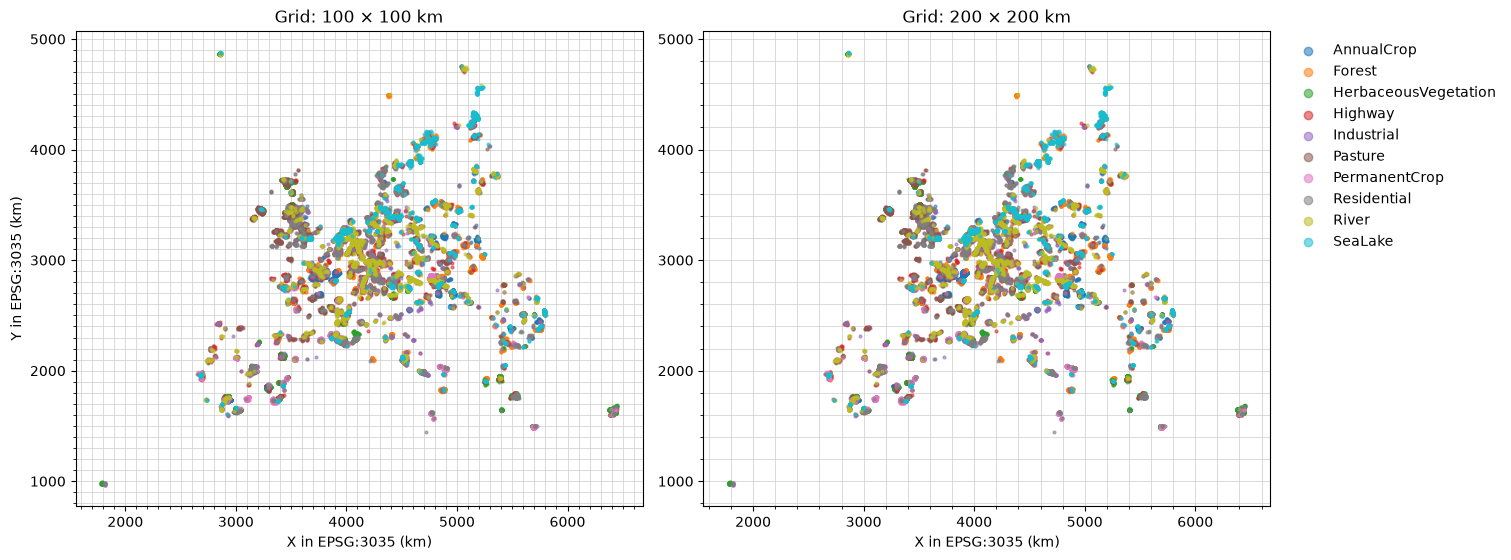

In [5]:
from matplotlib.ticker import MultipleLocator

fig, axes = plt.subplots(
    1, 2, figsize=(15, 8), layout="constrained"
)
class_names = sorted(inventory["class_name"].unique())
colors = plt.get_cmap("tab10")

for ax, grid_size_km in zip(axes, GRID_SIZES_KM):
    for color_idx, class_name in enumerate(class_names):
        group = inventory.loc[inventory["class_name"] == class_name]
        ax.scatter(
            group["x_3035_m"] / 1000,
            group["y_3035_m"] / 1000,
            s=4,
            alpha=0.55,
            color=colors(color_idx),
            label=class_name,
        )

    ax.set_title(f"Grid: {grid_size_km} × {grid_size_km} km")
    ax.set_xlabel("X in EPSG:3035 (km)")
    ax.set_aspect("equal", adjustable="box")
    ax.xaxis.set_major_locator(MultipleLocator(1000))
    ax.yaxis.set_major_locator(MultipleLocator(1000))
    ax.xaxis.set_minor_locator(MultipleLocator(grid_size_km))
    ax.yaxis.set_minor_locator(MultipleLocator(grid_size_km))
    ax.set_axisbelow(True)
    ax.grid(which="both", color="0.8", linewidth=0.5)

axes[0].set_ylabel("Y in EPSG:3035 (km)")
axes[1].legend(
    loc="upper left", bbox_to_anchor=(1.02, 1), markerscale=3, frameon=False
)
plt.show()


## Análisis de Duplicados

### Huellas dHash y distancia de Hamming

Calculamos dHash a partir de las bandas **B04, B03 y B02** de cada TIFF, en orden rojo, verde y azul.

Reducimos la imagen en gris a **9 columnas × 8 filas** mediante **LANCZOS** y comparamos cada píxel con su vecino derecho. Guardamos 1 si el vecino es más claro y 0 en caso contrario. Las 8 comparaciones por fila y las 8 filas producen una huella de **64 bits**.

La **distancia de Hamming** cuenta cuántos bits difieren entre dos huellas y toma valores de 0 a 64. Una distancia pequeña indica similitud según este resumen visual. Sin embargo, una distancia de cero puede corresponder a imágenes diferentes, porque hemos perdido color y detalle.


In [6]:
RGB_BANDS = (4, 3, 2)  # B04, B03 y B02
RGB_DISPLAY_MAX = 4000  # Solo para visualización


def read_rgb(image_path):
    with rasterio.open(image_path) as src:
        rgb = src.read(RGB_BANDS, out_dtype="float32")
    return np.moveaxis(rgb, 0, -1)


def read_grayscale(image_path):
    rgb = read_rgb(image_path)
    weights = np.array([0.299, 0.587, 0.114], dtype="float32")
    return Image.fromarray(rgb @ weights)


def compute_dhash(image_path):
    gray_image = read_grayscale(image_path)
    small_image = gray_image.resize((9, 8), Image.Resampling.LANCZOS)
    pixels = np.asarray(small_image)
    differences = pixels[:, 1:] > pixels[:, :-1]
    return differences.flatten()


def hamming_distance(hash_a, hash_b):
    return int(np.count_nonzero(hash_a != hash_b))


### Comprobación con dos imágenes

In [7]:
first_path = inventory.iloc[0]["path"]
second_path = inventory.iloc[1]["path"]

first_hash = compute_dhash(first_path)
second_hash = compute_dhash(second_path)

print("First image:", first_path)
print("Second image:", second_path)
print("First hash:", first_hash.astype(int))
print("Hash length:", first_hash.size)
print("Self-distance:", hamming_distance(first_hash, first_hash))
print("Pair distance:", hamming_distance(first_hash, second_hash))

First image: data/EuroSAT_MS/AnnualCrop/AnnualCrop_1.tif
Second image: data/EuroSAT_MS/AnnualCrop/AnnualCrop_10.tif
First hash: [0 0 0 1 1 0 0 1 1 1 0 1 1 0 0 1 1 1 0 0 1 0 1 0 1 1 0 0 0 0 1 0 0 1 1 1 1
 0 0 0 0 1 1 1 1 0 0 0 0 1 1 1 1 0 0 0 0 1 1 1 1 0 0 0]
Hash length: 64
Self-distance: 0
Pair distance: 36


### Visualización del redimensionado y de los bits

Comparamos la imagen en gris con dos versiones de 9 × 8 píxeles. Con **NEAREST** tomamos un píxel cercano para cada posición de salida y con **LANCZOS** combinamos información de varios. En el último panel vemos las 64 comparaciones de la versión LANCZOS.

Usamos `interpolation="nearest"` únicamente para mostrar los píxeles como bloques en la figura.

Antes de mostrar cada imagen, la convertimos a una matriz NumPy con `np.asarray(image)`. Así Matplotlib recibe las intensidades en coma flotante y aplica la escala de grises sin convertirlas a RGBA de 8 bits. 

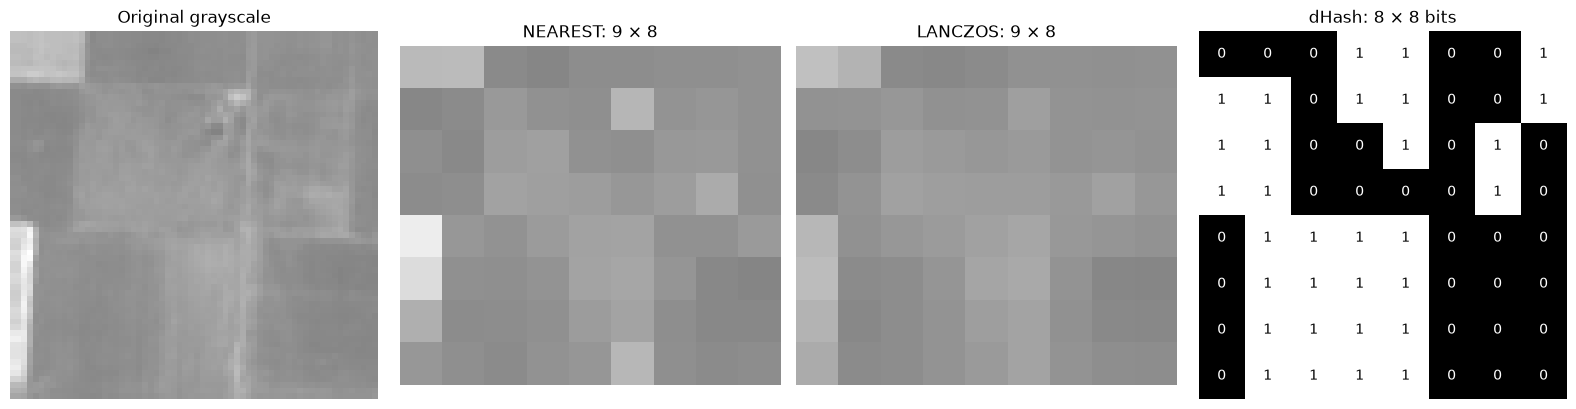

In [8]:
import matplotlib.pyplot as plt

image_path = inventory.iloc[0]["path"]
gray_image = read_grayscale(image_path)
nearest_image = gray_image.resize((9, 8), Image.Resampling.NEAREST)
lanczos_image = gray_image.resize((9, 8), Image.Resampling.LANCZOS)

pixels = np.asarray(lanczos_image)
hash_bits = pixels[:, 1:] > pixels[:, :-1]
gray_vmax = max(float(np.asarray(gray_image).max()), 1)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, image, title in zip(
    axes[:3],
    [gray_image, nearest_image, lanczos_image],
    ["Original grayscale", "NEAREST: 9 × 8", "LANCZOS: 9 × 8"],
):
    ax.imshow(np.asarray(image), cmap="gray", vmin=0, vmax=gray_vmax, interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")

axes[3].imshow(hash_bits, cmap="gray", interpolation="nearest")
for row, column in np.ndindex(hash_bits.shape):
    bit = int(hash_bits[row, column])
    axes[3].text(
        column, row, str(bit), ha="center", va="center",
        color="black" if bit else "white",
    )
axes[3].set_title("dHash: 8 × 8 bits")
axes[3].axis("off")
plt.tight_layout()
plt.show()


### Cálculo de las huellas del inventario

Calculamos una huella por imagen y las guardamos en `hashes`, una matriz de **27.000 filas y 64 columnas**. Cada fila corresponde a la imagen situada en la misma posición de `inventory`.


In [9]:
hashes = np.stack([
    compute_dhash(image_path)
    for image_path in tqdm(inventory["path"], desc="Computing dHash")
])

print("Hash matrix shape:", hashes.shape)

Computing dHash: 100%|██████████| 27000/27000 [00:35<00:00, 762.10it/s]

Hash matrix shape: (27000, 64)


### Grupos con huellas idénticas

Antes de aplicar un umbral, buscamos huellas completamente iguales, equivalentes a una distancia de Hamming de 0.

In [10]:
unique_hashes, group_ids, group_sizes = np.unique(hashes, axis=0, return_inverse=True, return_counts=True)

hash_inventory = inventory.copy()
hash_inventory["hash_group"] = group_ids
hash_inventory["group_size"] = group_sizes[group_ids]

candidates = hash_inventory.loc[hash_inventory["group_size"] > 1].copy()

print("Unique hashes:", len(unique_hashes))
print("Candidate groups:", candidates["hash_group"].nunique())
print("Candidate images:", len(candidates))

display(candidates.sort_values("hash_group").head(10))

Unique hashes: 27000
Candidate groups: 0
Candidate images: 0


,path,class_name,crs,x,y,longitude,latitude,x_3035_m,y_3035_m,grid_100km,grid_200km,hash_group,group_size


### Selección de imágenes representantes

Aplicamos el filtrado **dentro de cada clase**, con `MAX_HAMMING_DISTANCE = 5`. Elegimos la cuadrícula de **200 km** para el muestreo posterior y fijamos `RANDOM_SEED = 42`.

Recorremos las imágenes de cada clase en un orden aleatorio reproducible, para que la elección del representante no dependa de qué nombre de archivo aparece primero. Conservamos la primera imagen y comparamos cada nueva huella con todas las ya conservadas de esa clase. Si la distancia mínima es menor o igual que 5, la excluimos; en caso contrario, la conservamos.

La comparación se hace entre todas las celdas de una misma clase. Así también detectamos huellas parecidas situadas en celdas distintas. Los representantes conservados de cada clase tendrán distancias entre sí mayores que 5; esto no demuestra que todas las exclusiones sean duplicados reales.

En `filtered_inventory` guardamos los parches conservados con sus coordenadas y celdas. En `exclusion_log` registramos la ruta excluida, su representante, la distancia y las celdas de ambos. Revisaremos el efecto geográfico antes del muestreo. Un umbral menor exige huellas más parecidas para excluir una imagen; el valor 5 es una elección inicial que debemos inspeccionar.


In [11]:
MAX_HAMMING_DISTANCE = 5
GRID_SIZE_KM = 200
GRID_COLUMN = f"grid_{GRID_SIZE_KM}km"
RANDOM_SEED = 42

working_inventory = inventory.reset_index(drop=True)
keep_mask = np.zeros(len(working_inventory), dtype=bool)
excluded_records = []

for class_name, class_rows in tqdm(
    working_inventory.groupby("class_name", sort=True), desc="Filtering classes"
):
    retained_indices = []
    shuffled_rows = class_rows.sample(frac=1, random_state=RANDOM_SEED)

    for image_idx in shuffled_rows.index:
        if retained_indices:
            distances = np.count_nonzero(
                hashes[retained_indices] != hashes[image_idx], axis=1
            )
            nearest_position = int(distances.argmin())
            nearest_distance = int(distances[nearest_position])

            if nearest_distance <= MAX_HAMMING_DISTANCE:
                retained_idx = retained_indices[nearest_position]
                excluded_records.append({
                    "path": working_inventory.at[image_idx, "path"],
                    "class_name": class_name,
                    "grid_id": working_inventory.at[image_idx, GRID_COLUMN],
                    "matched_path": working_inventory.at[retained_idx, "path"],
                    "matched_grid_id": working_inventory.at[retained_idx, GRID_COLUMN],
                    "hamming_distance": nearest_distance,
                })
                continue

        retained_indices.append(image_idx)
        keep_mask[image_idx] = True

filtered_inventory = working_inventory.loc[keep_mask].copy().reset_index(drop=True)
exclusion_log = pd.DataFrame(
    excluded_records,
    columns=["path", "class_name", "grid_id", "matched_path", "matched_grid_id", "hamming_distance"],
)


Filtering classes: 100%|██████████| 10/10 [00:01<00:00,  6.93it/s]


### Reducción obtenida por clase y celda

Comparamos el inventario original con los parches conservados. `reduction_summary` muestra el efecto por clase y permite comprobar que quedan al menos 800 imágenes de cada una.

En `cell_reduction` hacemos la misma comparación para cada combinación **clase × celda de 200 km**, incluidas las que pierden todos sus parches. Esto permitirá comprobar si el conjunto filtrado puede cubrir las cuotas calculadas a partir del inventario original.

El muestreo tomará sus candidatos de `filtered_inventory`; usaremos las proporciones geográficas **anteriores al filtrado** como referencia para no ocultar los cambios producidos por dHash.


In [12]:
reduction_summary = pd.concat(
    [
        working_inventory.groupby("class_name").size().rename("before"),
        filtered_inventory.groupby("class_name").size().rename("after"),
    ], axis=1,
).fillna(0).astype(int)
reduction_summary["excluded"] = reduction_summary["before"] - reduction_summary["after"]

cell_reduction = pd.concat(
    [
        working_inventory.groupby(["class_name", GRID_COLUMN]).size().rename("before"),
        filtered_inventory.groupby(["class_name", GRID_COLUMN]).size().rename("after"),
    ], axis=1,
).fillna(0).astype(int)
cell_reduction.index.names = ["class_name", "grid_id"]
cell_reduction["excluded"] = cell_reduction["before"] - cell_reduction["after"]

if (reduction_summary["after"] < IMAGES_PER_CLASS).any():
    raise ValueError("Some classes have fewer than 800 images after dHash filtering.")

display(reduction_summary)
print("Remaining images:", len(filtered_inventory))
print("Excluded images:", len(exclusion_log))
print("Most affected class × cell groups:")
display(cell_reduction.sort_values("excluded", ascending=False).head(10))


,before,after,excluded
class_name,,,
AnnualCrop,3000,2999,1
Forest,3000,3000,0
HerbaceousVegetation,3000,3000,0
Highway,2500,2499,1
Industrial,2500,2500,0
Pasture,2000,2000,0
PermanentCrop,2500,2500,0
Residential,3000,3000,0
River,2500,2497,3


Remaining images: 26977
Excluded images: 23
Most affected class × cell groups:


before  after  excluded
class_name grid_id                         
SeaLake    21_16        74     69         5
           22_19       330    326         4
River      20_16        94     92         2
SeaLake    23_17       104    103         1
Highway    20_13        26     25         1
AnnualCrop 25_15        66     65         1
SeaLake    22_13        74     73         1
           22_16        99     98         1
River      20_14       153    152         1
SeaLake    14_8         10      9         1

### Inspección de pares excluidos

Mostramos un par de cada clase afectada: imagen excluida y representante en RGB, seguidos de sus bandas B08. Esto permite revisar el efecto del umbral también en el infrarrojo cercano, aunque B08 no se usa en dHash.

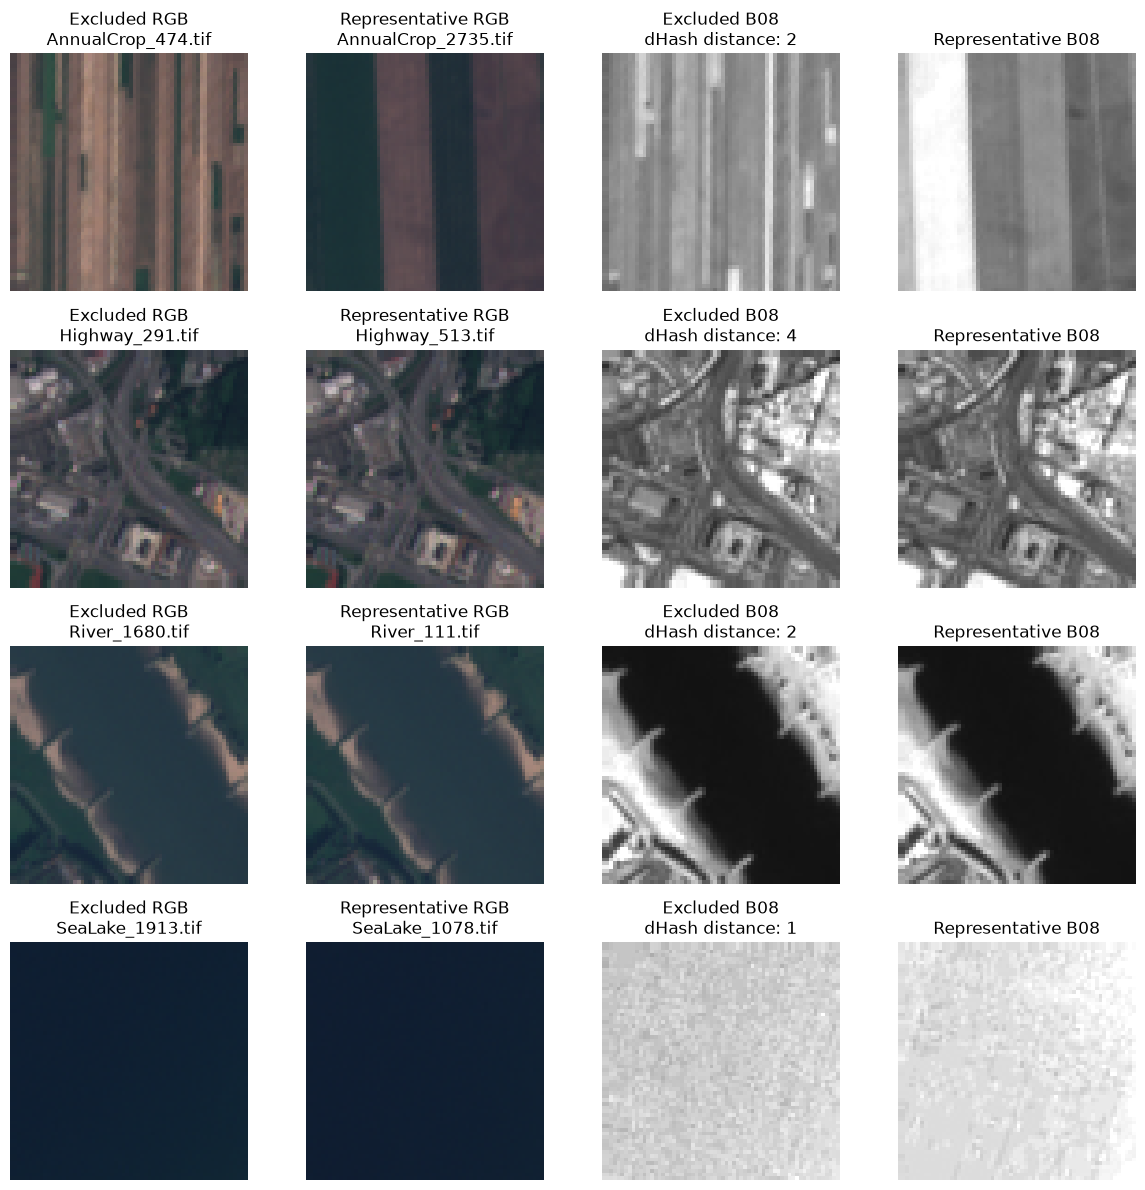

In [13]:
review_pairs = (
    exclusion_log.sort_values(["hamming_distance", "path"])
    .groupby("class_name", sort=True)
    .head(1)
    .sort_values("class_name")
)
fig, axes = plt.subplots(
    len(review_pairs), 4, figsize=(12, 3 * len(review_pairs)), squeeze=False
)
for row_idx, record in enumerate(review_pairs.itertuples(index=False)):
    for col, image_path in enumerate((record.path, record.matched_path)):
        axes[row_idx, col].imshow(np.clip(read_rgb(image_path) / RGB_DISPLAY_MAX, 0, 1))
        axes[row_idx, col].set_title(
            f"{'Excluded' if col == 0 else 'Representative'} RGB\n{Path(image_path).name}"
        )

    with rasterio.open(record.path) as src:
        excluded_nir = src.read(8, out_dtype="float32")
    with rasterio.open(record.matched_path) as src:
        matched_nir = src.read(8, out_dtype="float32")
    nir_vmax = max(float(np.percentile(np.stack([excluded_nir, matched_nir]), 98)), 1)
    axes[row_idx, 2].imshow(excluded_nir, cmap="gray", vmin=0, vmax=nir_vmax)
    axes[row_idx, 3].imshow(matched_nir, cmap="gray", vmin=0, vmax=nir_vmax)
    axes[row_idx, 2].set_title(f"Excluded B08\ndHash distance: {record.hamming_distance}")
    axes[row_idx, 3].set_title("Representative B08")
    for ax in axes[row_idx]:
        ax.axis("off")
plt.tight_layout()
plt.show()


### Interpretación de los pares revisados

En la prueba con umbral 5, `AnnualCrop_474.tif` y `AnnualCrop_2735.tif` tienen una distancia dHash de 2, pero la figura muestra campos diferentes con patrones de franjas verticales similares. Por tanto, este par es un ejemplo de similitud estructural que no equivale a un duplicado.

## Cuotas geográficas para el muestreo

Utilizamos la cuadrícula de **200 km** y las proporciones del **inventario original** dentro de cada clase. Para una celda con `before` imágenes y una clase con `class_total`, su cuota ideal es `800 × before / class_total`.

Convertimos esas cuotas en enteros mediante mayores restos:

1. Asignamos a cada celda la parte entera de su cuota ideal.
2. Calculamos cuántas imágenes faltan para llegar a 800 en la clase.
3. Sumamos una imagen a las celdas con mayor parte fraccionaria hasta completar 800. En caso de empate, ordenamos por `grid_id` para obtener un resultado reproducible.

Por ejemplo, para cuotas ideales `[3.6, 2.7, 1.7]`, cuya suma es 8, partimos de `[3, 2, 1]` y repartimos las dos plazas restantes a los restos 0.7 y 0.7: obtenemos `[3, 3, 2]`.

In [14]:
quota_tables = []

for class_name, class_cells in cell_reduction.reset_index().groupby("class_name", sort=True):
    class_cells = class_cells.sort_values("grid_id").reset_index(drop=True)
    class_total = int(class_cells["before"].sum())
    numerator = IMAGES_PER_CLASS * class_cells["before"]
    class_cells["ideal_quota"] = numerator / class_total

    # Cociente y resto enteros evitan errores de coma flotante al desempatar
    class_cells["quota"] = numerator // class_total
    class_cells["remainder"] = numerator % class_total
    missing = IMAGES_PER_CLASS - int(class_cells["quota"].sum())
    priority = class_cells.sort_values(
        ["remainder", "grid_id"], ascending=[False, True]
    ).index[:missing]
    class_cells.loc[priority, "quota"] += 1
    quota_tables.append(class_cells)

cell_quotas = pd.concat(quota_tables, ignore_index=True)
cell_quotas["grid_size_km"] = GRID_SIZE_KM

quota_summary = (
    cell_quotas.assign(zero_quota=cell_quotas["quota"].eq(0))
    .groupby("class_name")
    .agg(
        occupied_cells=("grid_id", "size"),
        zero_quota_cells=("zero_quota", "sum"),
        total_quota=("quota", "sum"),
    )
)

display(quota_summary)
print("Example cell quotas:")
display(cell_quotas.head(10).round(3))


,occupied_cells,zero_quota_cells,total_quota
class_name,,,
AnnualCrop,58,7,800
Forest,70,6,800
HerbaceousVegetation,41,3,800
Highway,116,12,800
Industrial,122,14,800
Pasture,72,10,800
PermanentCrop,51,9,800
Residential,119,22,800
River,86,17,800


Example cell quotas:


,class_name,grid_id,before,after,excluded,ideal_quota,quota,remainder,grid_size_km
0,AnnualCrop,14_10,1,1,0,0.267,0,800,200
1,AnnualCrop,14_8,100,100,0,26.667,27,2000,200
2,AnnualCrop,16_9,166,166,0,44.267,44,800,200
3,AnnualCrop,17_12,2,2,0,0.533,1,1600,200
4,AnnualCrop,17_13,64,64,0,17.067,17,200,200
5,AnnualCrop,17_15,3,3,0,0.800,1,2400,200
6,AnnualCrop,17_16,8,8,0,2.133,2,400,200
7,AnnualCrop,18_13,58,58,0,15.467,15,1400,200
8,AnnualCrop,18_14,353,353,0,94.133,94,400,200
9,AnnualCrop,18_15,3,3,0,0.800,1,2400,200


## Muestreo aleatorio dentro de cada clase y celda

Seleccionamos imágenes de `filtered_inventory` según las cuotas enteras de `cell_quotas`. Dentro de cada combinación **clase × celda**, hacemos un muestreo aleatorio sin reemplazo y fijamos `RANDOM_SEED = 42` para que sea reproducible.

El resultado `selected_inventory` contiene **800 imágenes por clase y 8.000 en total**, junto con sus coordenadas y sus identificadores de celda.

Comprobamos que se seleccionan 800 imágenes por clase, que cada celda aporta su cuota y que ninguna imagen se repite.

Guardamos en `data/processed/` el inventario seleccionado, las cuotas y el registro de exclusiones.


In [15]:
rng = np.random.default_rng(RANDOM_SEED)
quota_lookup = cell_quotas.set_index(["class_name", "grid_id"])["quota"]
selected_parts = []

for (class_name, grid_id), group in filtered_inventory.groupby(
    ["class_name", GRID_COLUMN], sort=True
):
    n_images = int(quota_lookup.loc[(class_name, grid_id)])
    if n_images > 0:
        selected_parts.append(
            group.sample(n=n_images, replace=False, random_state=rng)
        )

selected_inventory = (
    pd.concat(selected_parts, ignore_index=True)
    .sort_values(["class_name", "path"])
    .reset_index(drop=True)
)

selected_cell_counts = selected_inventory.groupby(
    ["class_name", GRID_COLUMN]
).size().rename("selected")
selected_cell_counts.index.names = ["class_name", "grid_id"]
sampling_check = (
    quota_lookup.to_frame()
    .join(selected_cell_counts)
    .fillna({"selected": 0})
)
sampling_check["selected"] = sampling_check["selected"].astype(int)
selected_class_counts = selected_inventory.groupby("class_name").size().reindex(
    reduction_summary.index, fill_value=0
)

assert selected_inventory["path"].is_unique
assert sampling_check["selected"].eq(sampling_check["quota"]).all()
assert selected_class_counts.eq(IMAGES_PER_CLASS).all()
assert len(selected_inventory) == IMAGES_PER_CLASS * len(reduction_summary)

PROCESSED_DIR = Path("data/processed")
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
selected_inventory.to_csv(PROCESSED_DIR / "eurosat_ms_800_inventory.csv", index=False)
cell_quotas.to_csv(PROCESSED_DIR / "eurosat_ms_800_quotas.csv", index=False)
exclusion_log.to_csv(PROCESSED_DIR / "eurosat_ms_dhash_exclusions.csv", index=False)

display(selected_class_counts.rename("selected").to_frame())
print("Selected images:", len(selected_inventory))
print("Selection records:", PROCESSED_DIR.resolve())


,selected
class_name,
AnnualCrop,800
Forest,800
HerbaceousVegetation,800
Highway,800
Industrial,800
Pasture,800
PermanentCrop,800
Residential,800
River,800


Selected images: 8000
Selection records: /Users/antonpg/Documents/UPM/Ciencia de datos/4. Cuarto Curso/Primer Semestre/Algoritmos y Arquitecturas para Procesado de Imágenes/Proyecto-AAPI/data/processed


### Copia de las imágenes seleccionadas

Copiamos únicamente los TIFF originales de `selected_inventory` a `data/EuroSAT_MS_800/`, manteniendo una subcarpeta por clase.

Cada ejecución elimina y vuelve a crear la carpeta de salida antes de copiar la selección actual. Así podemos repetir la celda sin errores y sin conservar imágenes de selecciones anteriores. Los TIFF del dataset original permanecen intactos.


In [17]:
OUTPUT_DIR = Path("data/EuroSAT_MS_800")

if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)

OUTPUT_DIR.mkdir(parents=True)

for record in tqdm(
    selected_inventory.itertuples(index=False),
    total=len(selected_inventory),
    desc="Copying selected images",
):
    source_path = Path(record.path)
    destination_dir = OUTPUT_DIR / record.class_name
    destination_dir.mkdir(exist_ok=True)

    destination_path = destination_dir / source_path.name
    shutil.copy2(source_path, destination_path)

print("Output directory:", OUTPUT_DIR.resolve())
print("Copied images:", len(list(OUTPUT_DIR.glob("*/*.tif"))))


Copying selected images: 100%|██████████| 8000/8000 [00:03<00:00, 2067.37it/s]

Output directory: /Users/antonpg/Documents/UPM/Ciencia de datos/4. Cuarto Curso/Primer Semestre/Algoritmos y Arquitecturas para Procesado de Imágenes/Proyecto-AAPI/data/EuroSAT_MS_800
Copied images: 8000


In [18]:
archive_path = shutil.make_archive(
    base_name=str(OUTPUT_DIR),
    format="zip",
    root_dir=str(OUTPUT_DIR.parent),
    base_dir=OUTPUT_DIR.name,
)

archive_path = Path(archive_path)

print("Archive:", archive_path.resolve())
print(f"Archive size: {archive_path.stat().st_size / 1024**2:.2f} MiB")

Archive: /Users/antonpg/Documents/UPM/Ciencia de datos/4. Cuarto Curso/Primer Semestre/Algoritmos y Arquitecturas para Procesado de Imágenes/Proyecto-AAPI/data/EuroSAT_MS_800.zip
Archive size: 586.18 MiB
